In [3]:
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import average_precision_score, confusion_matrix

files.upload()
files.upload()
df = pd.read_csv("creditcard.csv")
modelo = joblib.load("modelo_lightgbm.joblib")

Saving modelo_lightgbm.joblib to modelo_lightgbm (1).joblib


Saving creditcard.csv to creditcard (1).csv


In [4]:
X = df.drop(columns=["Class"])
y = df["Class"]

X_tmp, X_teste, y_tmp, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
X_treino, X_val, y_treino, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=42
)

# Valores originais em reais (antes do escalonamento), para o cálculo de custo
valor_val = X_val["Amount"].to_numpy().copy()
valor_teste = X_teste["Amount"].to_numpy().copy()

scaler = StandardScaler().fit(X_treino[["Amount", "Time"]])
X_treino = X_treino.copy()
X_val = X_val.copy()
X_teste = X_teste.copy()
for conj in (X_treino, X_val, X_teste):
    conj[["Amount", "Time"]] = scaler.transform(conj[["Amount", "Time"]])

In [5]:
prob_val = modelo.predict_proba(X_val)[:, 1]
print("PR-AUC validação:", round(average_precision_score(y_val, prob_val), 4))
print("Fraudes (treino, validação, teste):", y_treino.sum(), y_val.sum(), y_teste.sum())

PR-AUC validação: 0.7682
Fraudes (treino, validação, teste): 295 99 98


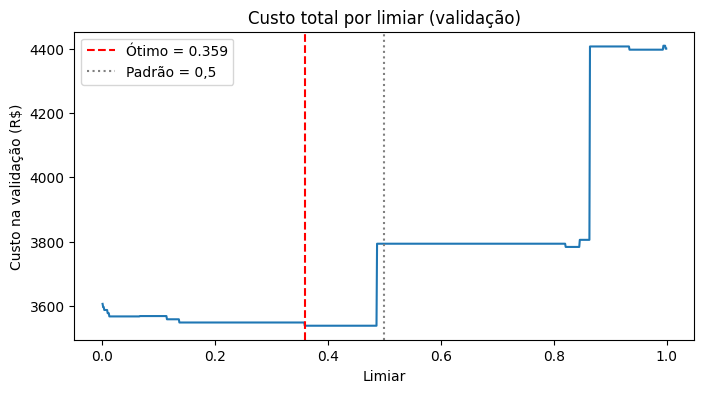

Limiar ótimo (validação): 0.359
Custo no ótimo: R$ 3,539.16


In [6]:
y_val_arr = y_val.to_numpy()
y_teste_arr = y_teste.to_numpy()

CUSTO_FP = 10.0  # R$ por transação legítima bloqueada (declarar no README)

def custo_total(y_true, prob, valor, limiar):
    bloqueada = prob >= limiar
    falsos_positivos = (bloqueada & (y_true == 0)).sum()
    perda_fraudes_passaram = valor[(~bloqueada) & (y_true == 1)].sum()
    return CUSTO_FP * falsos_positivos + perda_fraudes_passaram

limiares = np.linspace(0.001, 0.999, 999)
custos = np.array([custo_total(y_val_arr, prob_val, valor_val, t) for t in limiares])

idx = int(np.argmin(custos))
limiar_otimo = limiares[idx]

plt.figure(figsize=(8, 4))
plt.plot(limiares, custos)
plt.axvline(limiar_otimo, color="red", linestyle="--", label=f"Ótimo = {limiar_otimo:.3f}")
plt.axvline(0.5, color="gray", linestyle=":", label="Padrão = 0,5")
plt.xlabel("Limiar")
plt.ylabel("Custo na validação (R$)")
plt.title("Custo total por limiar (validação)")
plt.legend()
plt.show()

print(f"Limiar ótimo (validação): {limiar_otimo:.3f}")
print(f"Custo no ótimo: R$ {custos[idx]:,.2f}")

In [7]:
custo_nada_bloqueado = valor_val[y_val_arr == 1].sum()
custo_tudo_bloqueado = CUSTO_FP * (y_val_arr == 0).sum()
custo_limiar_05 = custo_total(y_val_arr, prob_val, valor_val, 0.5)

print(f"Não bloquear nada:   R$ {custo_nada_bloqueado:,.2f}")
print(f"Bloquear tudo:       R$ {custo_tudo_bloqueado:,.2f}")
print(f"Limiar padrão 0,5:   R$ {custo_limiar_05:,.2f}")
print(f"Limiar ótimo:        R$ {custos[idx]:,.2f}")

Não bloquear nada:   R$ 11,090.12
Bloquear tudo:       R$ 568,630.00
Limiar padrão 0,5:   R$ 3,793.92
Limiar ótimo:        R$ 3,539.16


In [8]:
prob_teste = modelo.predict_proba(X_teste)[:, 1]
pred_teste = (prob_teste >= limiar_otimo).astype(int)

tn, fp, fn, tp = confusion_matrix(y_teste_arr, pred_teste).ravel()
precisao = tp / (tp + fp) if (tp + fp) > 0 else 0
recall = tp / (tp + fn)

print(f"Limiar fixado na validação: {limiar_otimo:.3f}")
print(f"Verdadeiros positivos (fraudes bloqueadas): {tp}")
print(f"Falsos positivos (legítimas bloqueadas):    {fp}")
print(f"Falsos negativos (fraudes que passaram):    {fn}")
print(f"Precisão: {precisao:.3f}   Recall: {recall:.3f}")
print(f"Fraudes bloqueadas em R$: {valor_teste[(pred_teste == 1) & (y_teste_arr == 1)].sum():,.2f}")
print(f"Custo total no teste: R$ {custo_total(y_teste_arr, prob_teste, valor_teste, limiar_otimo):,.2f}")
print(f"PR-AUC no teste: {average_precision_score(y_teste_arr, prob_teste):.4f}")

Limiar fixado na validação: 0.359
Verdadeiros positivos (fraudes bloqueadas): 72
Falsos positivos (legítimas bloqueadas):    6
Falsos negativos (fraudes que passaram):    26
Precisão: 0.923   Recall: 0.735
Fraudes bloqueadas em R$: 6,716.94
Custo total no teste: R$ 3,987.99
PR-AUC no teste: 0.8343


In [9]:
with open("limiar.txt", "w") as f:
    f.write(f"{limiar_otimo:.3f}")
files.download("limiar.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
for cfp in [5, 10, 20, 50]:
    CUSTO_FP = float(cfp)
    c = np.array([custo_total(y_val_arr, prob_val, valor_val, t) for t in limiares])
    print(f"Custo FP = R$ {cfp:>3}: limiar ótimo = {limiares[np.argmin(c)]:.3f}")

Custo FP = R$   5: limiar ótimo = 0.359
Custo FP = R$  10: limiar ótimo = 0.359
Custo FP = R$  20: limiar ótimo = 0.359
Custo FP = R$  50: limiar ótimo = 0.359


In [11]:
CUSTO_FP = 10